# Carinthia SEM Dataset — Initial Exploratory Data Analysis

This notebook explores the Carinthia dataset metadata CSV and its SEM images. It covers CSV parsing, schema and data quality, class balance, image-file availability, image dimensions and pixel summaries, and visual samples by class.

The CSV shown in the project description uses a **semicolon (`;`) delimiter**. The labels are treated as categorical codes. Add human-readable class names only after checking the dataset documentation. The published Zenodo record describes 4,591 grayscale SEM images across six unevenly represented classes.

**Input expected:** the metadata CSV with `image_path`, `file_name`, and `label` columns, plus the extracted image files. Set the paths in the next cell.


## 1. Imports and paths

If the notebook is inside the extracted dataset folder, the defaults may work as written. Otherwise set `CSV_PATH` and `DATA_ROOT` to your local paths. `DATA_ROOT` should be the folder against which paths such as `data/images/example.jpg` are resolved.

In [8]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

# Edit these two paths for your machine.
CSV_PATH = Path("Data\carinthia.csv")
DATA_ROOT = Path("Data")

# The sample CSV is semicolon-separated. Set to None to let pandas infer the delimiter.
CSV_SEPARATOR = ";"

RANDOM_SEED = 42
N_SAMPLE_IMAGES_PER_CLASS = 8


<>:11: SyntaxWarning: invalid escape sequence '\c'
<>:11: SyntaxWarning: invalid escape sequence '\c'
C:\Users\kumar\AppData\Local\Temp\ipykernel_27244\1196101643.py:11: SyntaxWarning: invalid escape sequence '\c'
  CSV_PATH = Path("Data\carinthia.csv")


## 2. Load the metadata CSV

The loader trims whitespace from column names and values. It preserves labels as strings so codes such as `1` through `6` remain categorical identifiers rather than measurements.

In [9]:
if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"CSV not found: {CSV_PATH.resolve()}\n"
        "Update CSV_PATH in the paths cell above."
    )

metadata = pd.read_csv(CSV_PATH, sep=CSV_SEPARATOR, dtype={"label": "string"})
metadata.columns = metadata.columns.str.strip()

for column in metadata.select_dtypes(include=["object", "string"]).columns:
    metadata[column] = metadata[column].str.strip()

required_columns = {"image_path", "file_name", "label"}
missing_columns = required_columns - set(metadata.columns)
if missing_columns:
    raise ValueError(
        f"Missing expected columns: {sorted(missing_columns)}. "
        f"Columns found: {metadata.columns.tolist()}"
    )

print(f"Rows: {len(metadata):,}")
print(f"Columns: {metadata.columns.tolist()}")
display(metadata.head())


Rows: 4,591
Columns: ['image_path', 'file_name', 'label']


,image_path,file_name,label
0,data/images/2661734b21874fdf9e35a4319a9e7462.jpg,2661734b21874fdf9e35a4319a9e7462.jpg,6
1,data/images/0c8af9b8e62f4cb498392e806236e5e0.jpg,0c8af9b8e62f4cb498392e806236e5e0.jpg,6
2,data/images/ecb33a23f90b47fe8ee1dfe3e4d5f0df.jpg,ecb33a23f90b47fe8ee1dfe3e4d5f0df.jpg,6
3,data/images/adc88a3f9fb34ae79142ba9f12a6f1e1.jpg,adc88a3f9fb34ae79142ba9f12a6f1e1.jpg,6
4,data/images/bc228459f662459f80fbce99bedd9d20.jpg,bc228459f662459f80fbce99bedd9d20.jpg,6


## 3. Basic structure and data quality

Check whether each row has the fields needed for analysis, whether rows or filenames repeat, and whether image paths are unique. Duplicate filenames should be interpreted in the context of the dataset structure before removing anything.

In [10]:
print("Data types:")
display(metadata.dtypes.to_frame("dtype"))

print("Missing values by column:")
display(metadata.isna().sum().rename("missing_count").to_frame())

print(f"Exact duplicate rows: {metadata.duplicated().sum():,}")
print(f"Duplicate image_path values: {metadata['image_path'].duplicated().sum():,}")
print(f"Duplicate file_name values: {metadata['file_name'].duplicated().sum():,}")

print("Unique labels:")
display(pd.Series(sorted(metadata["label"].dropna().unique()), name="label_code").to_frame())


Data types:


,dtype
image_path,str
file_name,str
label,string


Missing values by column:


,missing_count
image_path,0
file_name,0
label,0


Exact duplicate rows: 0
Duplicate image_path values: 0
Duplicate file_name values: 0
Unique labels:


,label_code
0,1
1,2
2,3
3,4
4,5
5,6


## 4. Class distribution

Counts and percentages show how uneven the label distribution is. This matters when planning later train/validation/test splits and selecting evaluation metrics. Accuracy alone can hide poor performance on rare classes.

,image_count,percent
label,,
1,55,1.2
2,8,0.17
3,4008,87.3
4,289,6.29
5,4,0.09
6,227,4.94


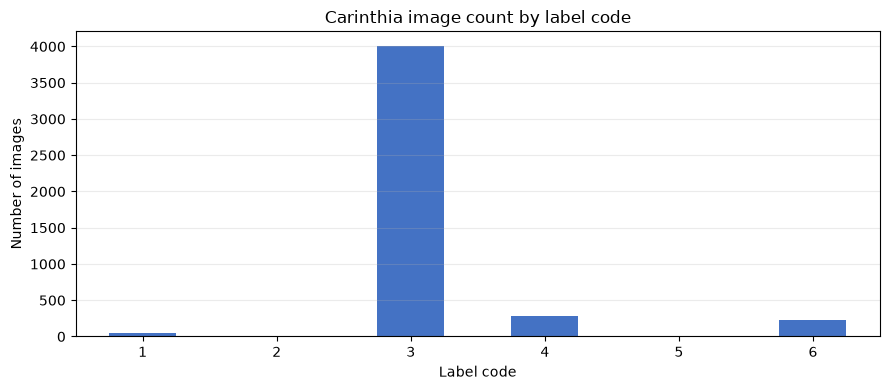

In [11]:
class_counts = metadata["label"].value_counts(dropna=False).sort_index()
class_summary = pd.DataFrame({
    "image_count": class_counts,
    "percent": (class_counts / len(metadata) * 100).round(2),
})
display(class_summary)

ax = class_counts.plot(kind="bar", figsize=(9, 4), color="#4472C4")
ax.set_title("Carinthia image count by label code")
ax.set_xlabel("Label code")
ax.set_ylabel("Number of images")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Resolve image paths and check file availability

The CSV stores paths such as `data/images/<filename>.jpg`. The resolver first checks `DATA_ROOT / image_path`, then the CSV folder. If your files are arranged differently, edit `DATA_ROOT` or the resolver candidates below.

In [13]:
def resolve_image_path(row):
    relative_path = Path(str(row["image_path"]))
    filename = str(row["file_name"])

    candidates = [
        DATA_ROOT / relative_path,
        CSV_PATH.parent / relative_path,
        # Your layout: Data/images/<filename>
        CSV_PATH.parent / Path(*relative_path.parts[1:])
        if relative_path.parts and relative_path.parts[0].lower() == "data"
        else CSV_PATH.parent / relative_path,
        CSV_PATH.parent / "images" / filename,
    ]

    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()

    return candidates[0].resolve()

metadata["resolved_image_path"] = metadata.apply(resolve_image_path, axis=1)
metadata["image_exists"] = metadata["resolved_image_path"].map(lambda p: Path(p).is_file())

print(f"Image files found: {metadata['image_exists'].sum():,} / {len(metadata):,}")
print(f"Image files missing: {(~metadata['image_exists']).sum():,}")
display(metadata.loc[~metadata["image_exists"], ["image_path", "file_name", "label"]].head(10))

if metadata["image_exists"].any():
    print("Example resolved path:", metadata.loc[metadata["image_exists"], "resolved_image_path"].iloc[0])


Image files found: 4,591 / 4,591
Image files missing: 0


,image_path,file_name,label


Example resolved path: C:\Users\kumar\Documents\Repos\one-class-nuisance-filter\Data\images\2661734b21874fdf9e35a4319a9e7462.jpg
